In [6]:
%load_ext autoreload
%autoreload 2 --full

import pipeline
import networkx as nx
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import sys
import seaborn as sns
from itertools import count

import plotly.io as pio
pio.renderers.default = "notebook"

seed=21

def setup(agg, interval):

    if agg:
        save_dir = Path(f'data/agg')
        save_dir.mkdir(parents=True, exist_ok=True)
        if interval == 6:
            fpath_pos = Path('data/agg/DEP_NET_UNDIRECT_GEOTAX11_14460_20190101_20191231_Tc6_Ts1.csv.gz')
            fpath_neg = Path('data/agg/DEP_NET_UNDIRECT_NEG_GEOTAX11_14460_20190101_20191231_Tc6_Ts1.csv.gz')
            print(f"Returning external agg split (interval={interval}")
            return save_dir, fpath_pos, fpath_neg
        elif interval == 24:
            fpath = Path('data/agg/geotax_complete_24h.pkl')
        else:
            print("Invalid time range (must be 24 or 6)")
        print(f"Returning agg network: interval={interval}")
    else:
        if interval == 6:
            fpath = Path('data/poi_level/6h/DEP_NET_UNDIRECT_14460_20190101_20191231_Tc6_Ts1.csv.gz')
            save_dir = Path(f'data/poi_level/6h')
        elif interval == 24:
            fpath = Path('data/poi_level/24h/0_network_24h.txt')
            save_dir = Path(f'data/poi_level/24h')
        else:
            print("Invalid time range (must be 24 or 6)")
        print(f"Returning POI network: interval={interval}")

    save_dir.mkdir(parents=True, exist_ok=True)

    return save_dir, fpath

# fn for quick network overview
def exam(df):
    print(df.info())
    print(df.head())

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### POI Network Examination

In [ ]:
# setup

save_dir, fpath = setup(seed, False, 6)

df_poi = pipeline.fast_read_csv(fpath)

exam(df_poi)

Interval: 6 hrs | agg: False | Seed: 21
<class 'pandas.DataFrame'>
RangeIndex: 13604739 entries, 0 to 13604738
Data columns (total 17 columns):
 #   Column                Dtype  
---  ------                -----  
 0   ORIGIN                str    
 1   DESTINATION           str    
 2   TAXONOMY_ORIGIN       str    
 3   TAXONOMY_DESTINATION  str    
 4   GEOID_ORIGIN          int64  
 5   GEOID_DESTINATION     int64  
 6   LAT_ORIGIN            float32
 7   LNG_ORIGIN            float32
 8   LAT_DESTINATION       float32
 9   LNG_DESTINATION       float32
 10  DIST_KM               float32
 11  N_COVISITS            int64  
 12  N_UIDS_ORIGIN         int64  
 13  N_VISITS_ORIGIN       int64  
 14  N_UIDS_DESTINATION    float64
 15  N_VISITS_DESTINATION  float64
 16  DEP                   float32
dtypes: float32(6), float64(2), int64(5), str(4)
memory usage: 1.4 GB
None
                ORIGIN          DESTINATION     TAXONOMY_ORIGIN  \
0  223-222@62j-sj7-jvz  zzy-22m@62j-qp2-fpv  Auto

### Agg Network Examination

In [ ]:
# setup

save_dir, fpath_pos, fpath_neg = setup(seed, True, 6)

df_pos = pipeline.fast_read_csv(fpath_pos)
df_neg = pipeline.fast_read_csv(fpath_neg)

exam(df_pos)
exam(df_neg)

<class 'pandas.DataFrame'>
RangeIndex: 4620138 entries, 0 to 4620137
Data columns (total 16 columns):
 #   Column            Dtype   
---  ------            -----   
 0   NODE_A            category
 1   NODE_B            category
 2   N_COVISITS        float32 
 3   N_UIDS_A          float32 
 4   N_POIS_A          float32 
 5   N_VISITS_A        float32 
 6   N_UIDS_B          float32 
 7   N_POIS_B          float32 
 8   N_VISITS_B        float32 
 9   DEP               float32 
 10  DIST_KM_CENTROID  float32 
 11  BIN               int64   
 12  SPLIT             str     
 13  DIST_KM_MIN       float32 
 14  DIST_KM_MEDIAN    float32 
 15  DIST_KM_MEAN      float32 
dtypes: category(2), float32(12), int64(1), str(1)
memory usage: 300.9 MB
None
                              NODE_A                            NODE_B  \
0                25021404302_Grocery        25025000803_Transportation   
1           25009211300_Coffee / Tea              25009266300_Industry   
2               25017

In [ ]:
# check that train_pos contains all nodes
def node_counter(df, y=False):
    train = df[df['SPLIT'] == 'TRAIN']
    test = df[df['SPLIT'] == 'TEST']
    n_train = len(np.unique(train[['NODE_A', 'NODE_B']].dropna()))
    n_test = len(np.unique(test[['NODE_A', 'NODE_B']].dropna()))
    return (train, n_train, n_test) if y else (n_train, n_test)

train_pos, n_train_pos, n_test_pos = node_counter(df_pos, y=True)
n_train_neg, n_test_neg = node_counter(df_neg)

is_complete = bool(n_train_pos == n_test_pos == n_train_neg == n_test_neg)
print(f'Complete: {is_complete}')
print(
    f'train_pos: {n_train_pos}\ntrain_neg: {n_train_neg}\ntest_pos: {n_test_pos}\ntest_neg: {n_test_neg}'
)

def node_set(df, split):
    d = df[df['SPLIT'] == split][['NODE_A', 'NODE_B']].dropna()
    return set(pd.unique(d.values.ravel()))

train_pos_nodes = node_set(df_pos, 'TRAIN')
missing = {
    'test_pos':  node_set(df_pos, 'TEST')  - train_pos_nodes,
    'train_neg': node_set(df_neg, 'TRAIN') - train_pos_nodes,
    'test_neg':  node_set(df_neg, 'TEST')  - train_pos_nodes,
}
print(f'Complete: {all(not v for v in missing.values())}')
for k, v in missing.items():
    print(f'{k}: {len(v)} nodes absent from train_pos'
          + (f' (e.g. {sorted(v)[:3]})' if v else ''))


# check connectivity
G = nx.from_pandas_edgelist(train_pos, 'NODE_A', 'NODE_B')
print(f'Connected: {nx.is_connected(G)}')

In [ ]:
#plt.semilogx(df['N_COVISITS'].value_counts())
print(df['N_COVISITS'].value_counts())
print(f'{df["N_COVISITS"].isna().sum()} nulls')

print('\nDEP descriptive stats')
plt.semilogx(df['DEP'].value_counts())
print(df['DEP'].describe())
print(f'{df["DEP"].isna().sum()} nulls')

In [3]:
# checking unmatched distribution of weak vs strong class

trainfile = 'data/train.txt'
G_train = nx.read_edgelist(
    trainfile, data=[('weight', float)], delimiter='\t')
train_pos_edges = [tuple(sorted(e)) for e in G_train.edges()]

def _dep(edges, keep):
    return np.array([G[u][v]['DEP'] for u, v in edges],
                    dtype=np.float64)[keep]

keep_train_pos = list(range(len(train_pos_edges)))
keep_test_pos = list(range(len(test_pos_edges)))

# save original index order to match back to G
edges_train = np.array(train_pos_edges, dtype=object)
edges_test = np.array(test_pos_edges, dtype=object)
edges_all = np.concatenate((edges_train, edges_test))

# deps

dep_train = _dep(train_pos_edges, keep_train_pos)
dep_test = _dep(test_pos_edges, keep_test_pos)
dep_all = np.concatenate((dep_train, dep_test))

dep_train, edges_train = dep_train[dep_train > 0], edges_train[dep_train > 0]
dep_test, edges_test = dep_test[dep_test > 0], edges_test[dep_test > 0]
dep_all, edges_all = dep_all[dep_all > 0], edges_all[dep_all > 0]

# actual sorted edges plus indices of sorted edges for later lookup
train_order, test_order, all_order = np.argsort(dep_train), np.argsort(dep_test), np.argsort(dep_all)
dep_train, edges_train = dep_train[train_order], edges_train[train_order]
dep_test, edges_test = dep_test[test_order], edges_test[test_order]
dep_all, edges_all = dep_all[all_order], edges_all[all_order]

# fit on train only to match pipeline behavior
thr = np.quantile(dep_train, 0.5)

train_mask = dep_train > thr
dep_train_strong, edges_train_strong = dep_train[train_mask], edges_train[train_mask]
dep_train_weak, edges_train_weak = dep_train[~train_mask], edges_train[~train_mask]

test_mask = dep_test > thr
dep_test_strong, edges_test_strong = dep_test[test_mask], edges_test[test_mask]
dep_test_weak, edges_test_weak = dep_test[~test_mask], edges_test[~test_mask]

all_mask = dep_all > thr
dep_all_strong, edges_all_strong = dep_all[all_mask], edges_all[all_mask]
dep_all_weak, edges_all_weak = dep_all[~all_mask], edges_all[~all_mask]

# distances

def _dist(edges):
    return np.array([G[u][v]['DIST_KM_MEAN'] for u, v in edges], dtype=np.float32)

dist_train_strong = _dist(edges_train_strong)
dist_train_weak = _dist(edges_train_weak)
dist_train = _dist(edges_train)
dist_test_strong = _dist(edges_test_strong)
dist_test_weak = _dist(edges_test_weak)
dist_test = _dist(edges_test)
dist_all_strong = _dist(edges_all_strong)
dist_all_weak = _dist(edges_all_weak)
dist_all = _dist(edges_all)


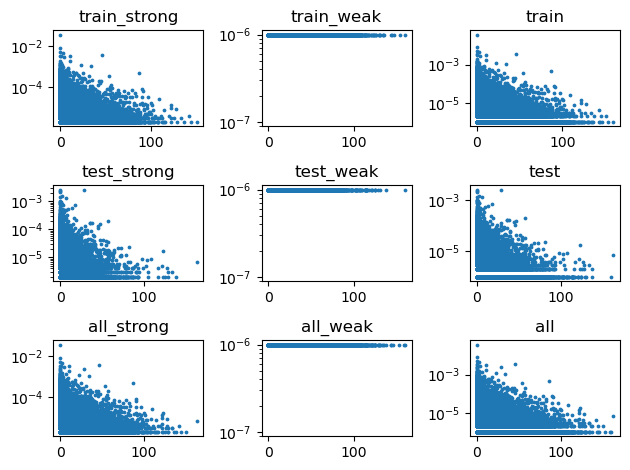

In [16]:
# plot dep against distance

fig, ax = plt.subplots(3, 3)

order = [
    (dist_train_strong, dep_train_strong),
    (dist_train_weak, dep_train_weak), 
    (dist_train, dep_train),
    (dist_test_strong, dep_test_strong), 
    (dist_test_weak, dep_test_weak), 
    (dist_test, dep_test),
    (dist_all_strong, dep_all_strong), 
    (dist_all_weak, dep_all_weak), 
    (dist_all, dep_all)
]
titles = ['train_strong', 'train_weak', 'train',
         'test_strong', 'test_weak', 'test',
         'all_strong', 'all_weak', 'all']

cur_row_idx = 0
cur_col_idx = 0
for i, (dist_class, dep_class) in enumerate(order):
    ax[cur_row_idx, cur_col_idx].scatter(dist_class, dep_class, s=3)
    ax[cur_row_idx, cur_col_idx].set_title(titles[i])
    # ax[cur_row_idx, cur_col_idx].set_xscale('log')
    ax[cur_row_idx, cur_col_idx].set_yscale('log')
    if i in [2, 5]:
        cur_col_idx = 0
        cur_row_idx += 1
    else:
        cur_col_idx += 1

plt.tight_layout()
plt.savefig('figures/agg/temp/strength_dep_dist_logy.png')

In [4]:
# isolate distance-controlling to see its behavior

def _dist_matched_idx(dep, dist, thr):
    # same log bins as the link version, then keep min(#strong, #weak)
    strong = dep > thr
    if dist.max() > 0.01:
        edges_b = np.concatenate(
            ([0], np.geomspace(0.01, dist.max(), 50)))
    else:
        edges_b = np.linspace(0, dist.max() + 1e-5, 50)
    # indexes the bin that each edge falls into
    b = np.digitize(dist, edges_b)
    keep = []
    for bin_id in np.unique(b):
        # strong and weak within bin (returns indices)
        in_bin = np.where(b == bin_id)[0]
        s = in_bin[strong[in_bin]]
        w = in_bin[~strong[in_bin]]
        k = min(len(s), len(w))
        if k == 0:
            continue
        # select k random samples from within-bin subsets w/o replacement
        # (smaller one technically just gets copied but its fast enough
        # that the redundancy doesn't matter)
        keep.extend(np.random.choice(s, k, replace=False))
        keep.extend(np.random.choice(w, k, replace=False))
    return np.sort(np.array(keep, dtype=int))

idx_tr = _dist_matched_idx(dep_train, dist_train, thr)
idx_te = _dist_matched_idx(dep_test, dist_test, thr)

# filter dep/edges/dist down to the matched subset
dep_train_matched, edges_train_matched, dist_train_matched = (
    dep_train[idx_tr], edges_train[idx_tr], dist_train[idx_tr])
dep_test_matched, edges_test_matched, dist_test_matched = (
    dep_test[idx_te], edges_test[idx_te], dist_test[idx_te])

y_str_train_matched = (dep_train_matched > thr).astype(int)
y_str_test_matched = (dep_test_matched > thr).astype(int)

print(f"Distance-matched strength set: "
      f"train {len(idx_tr)}/{len(dep_train)}, "
      f"test {len(idx_te)}/{len(dep_test)} edges kept")
if len(np.unique(y_str_test_matched)) < 2 or len(np.unique(y_str_train_matched)) < 2:
    print("Warning: a strength class vanished after distance "
          "matching — cannot score.")

Distance-matched strength set: train 314420/523964, test 104900/174356 edges kept


In [9]:
# confirm the floor pileup in nonzero DEP

floor_val = np.float32(1e-6)
n_at_floor = (dep_all == floor_val).sum()
print(f"Nonzero DEP edges: {len(dep_all)}")
print(f"Edges exactly at floor ({floor_val}): {n_at_floor} ({n_at_floor / len(dep_all):.2%})")

# most common nonzero DEP values
vals, counts = np.unique(dep_all, return_counts=True)
order = np.argsort(counts)[::-1]
print("\nTop 10 most common nonzero DEP values:")
for v, c in zip(vals[order][:10], counts[order][:10]):
    print(f"  {v:.6e} : {c} edges ({c / len(dep_all):.2%})")

# quantile sweep to see where the distribution escapes the floor pileup
print("\nQuantile sweep:")
for q in [0.5, 0.7, 0.8, 0.87, 0.9, 0.95, 0.99]:
    print(f"  q={q:.2f} -> {np.quantile(dep_all, q):.6e}")

Nonzero DEP edges: 698320
Edges exactly at floor (9.999999974752427e-07): 451068 (64.59%)

Top 10 most common nonzero DEP values:
  1.000000e-06 : 451068 edges (64.59%)
  2.000000e-06 : 107247 edges (15.36%)
  3.000000e-06 : 46714 edges (6.69%)
  4.000000e-06 : 25130 edges (3.60%)
  5.000000e-06 : 15469 edges (2.22%)
  6.000000e-06 : 10132 edges (1.45%)
  7.000000e-06 : 7260 edges (1.04%)
  8.000000e-06 : 5232 edges (0.75%)
  9.000000e-06 : 4122 edges (0.59%)
  1.000000e-05 : 3267 edges (0.47%)

Quantile sweep:
  q=0.50 -> 1.000000e-06
  q=0.70 -> 2.000000e-06
  q=0.80 -> 3.000000e-06
  q=0.87 -> 4.000000e-06
  q=0.90 -> 4.000000e-06
  q=0.95 -> 8.000000e-06
  q=0.99 -> 2.500000e-05


### Agg Node Lat/Lon Addition

In [ ]:
''' 
- match pois to nodes
- load in both dfs (filter poi df to tax, geoid, coords)
- split into origin and destination dfs; concat and dedupe
- slice off geoid col to get tract
- create new col AGG_ID to match agg nodes (TRACT_TAX)
- group by AGG_ID and average coords; rename centroids and delete used df
- merge on AGG_ID
- save new files as csv
'''

orig_cols = ['ORIGIN'] + [c for c in df_poi.columns if c.endswith('_ORIGIN')]
dest_cols = ['DESTINATION'] + [c for c in df_poi.columns if c.endswith('_DESTINATION')]
orig = df_poi[orig_cols]
dest = df_poi[dest_cols]

def de_edgify(df, indicator):
    col_names = df.columns.tolist()
    mapper = {n: n.replace(indicator, '') for n in col_names}
    indicator2 = indicator.replace('_', '')
    mapper |= {indicator2: 'POI'}
    return df.rename(mapper, axis=1)

orig = de_edgify(orig, '_ORIGIN')
dest = de_edgify(dest, '_DESTINATION')

poi_df = pd.concat([orig, dest], ignore_index=True)

# check for multiple vals before deduping
nu = poi_df.groupby('POI')[['LAT','LNG']].nunique()
print(f'Max unique vals: {nu.max()}')
if (nu.max() > 1).any():
    problem_cols = nu.columns[nu.max() > 1]
    for col in problem_cols:
        print(f"\n{col}: {(nu[col] > 1).sum()} POIs with >1 value")
        print(nu.loc[nu[col] > 1, col].describe())
    if input("Still continue? Y/N") in ('n', 'N'):
        sys.exit()
else:
    print("We good.")

poi_df = poi_df.drop_duplicates(subset='POI')
poi_df['AGG_ID'] = poi_df['GEOID'].astype(str).str[:11] + '_' + poi_df['TAXONOMY']

centroids = poi_df.groupby('AGG_ID')[['LAT', 'LNG']].mean().reset_index()

del poi_df

a = centroids.rename(columns={'AGG_ID': 'NODE_A', 'LAT': 'LAT_A', 'LNG': 'LNG_A'})
b = centroids.rename(columns={'AGG_ID': 'NODE_B', 'LAT': 'LAT_B', 'LNG': 'LNG_B'})

df_pos_extended = df_pos.merge(a, on='NODE_A', how='left', validate='many_to_one').merge(b, on='NODE_B', how='left', validate='many_to_one')
df_neg_extended = df_neg.merge(a, on='NODE_A', how='left', validate='many_to_one').merge(b, on='NODE_B', how='left', validate='many_to_one')

print(f"Positive NaNs: {df_pos_extended[['LAT_A', 'LNG_A', 'LAT_B', 'LNG_B']].isna().sum()}")
print(f"Negative NaNs: {df_neg_extended[['LAT_A', 'LNG_A', 'LAT_B', 'LNG_B']].isna().sum()}")

In [4]:
# save
df_pos_extended.to_csv(save_dir / 'geotax_extended_6h_pos.csv.gz', index=False)
df_neg_extended.to_csv(save_dir / 'geotax_extended_6h_neg.csv.gz', index=False)

### Thresholded Network Build (POI-level)

Returning POI network: interval=6
count    100000.000000
mean          0.000009
std           0.000104
min           0.000000
25%           0.000000
50%           0.000001
75%           0.000005
max           0.022222
Name: DEP, dtype: float64


c:\Users\User\anaconda3\envs\depnet\Lib\site-packages\pandas\core\nanops.py:1020: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


Total edges: 13604737
Zero-DEP edges: 3662885
Nonzero DEP range: [1.00e-06, 5.00e-01]


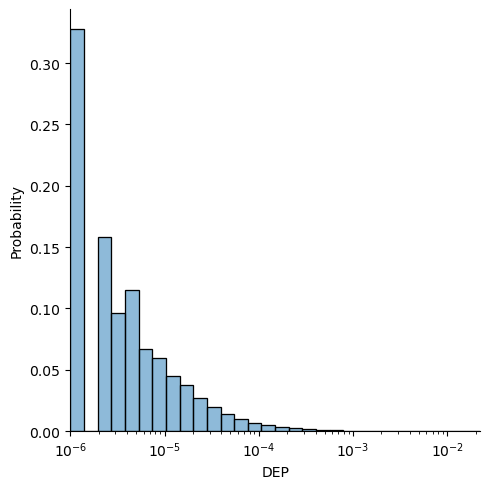

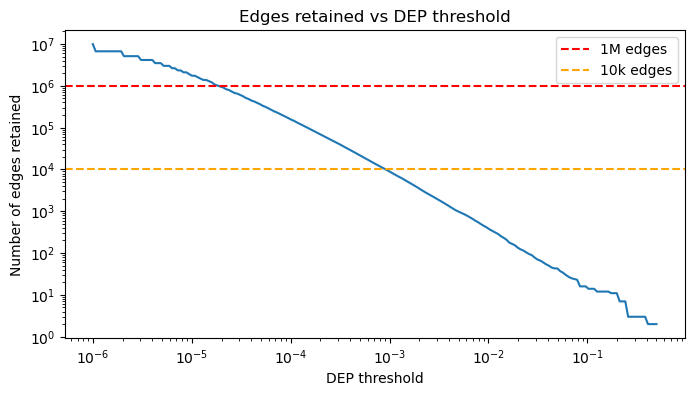

DEP_low (~1M): DEP â‰ˆ 1.820010e-05, edges retained = 1015855
DEP_high (~10k): DEP â‰ˆ 8.906727e-04, edges retained = 10361


In [7]:
# --- dependency distribution ---

save_dir, data = setup(False, 6)

# reading in + dealing with missing values
df = pd.read_csv(data)
df['DEP'] = pd.to_numeric(df['DEP'], errors='coerce')
df = df.dropna(subset=['DEP'])

# sampling for performance before plotting
plot_data = df['DEP'].sample(100000)
print(plot_data.describe())

sns.displot(plot_data, bins=30, kde=True, stat='probability', log_scale=True)
plt.margins(x=0)

# --- num removed vs binned values ---

# dep_nonzero = every nonzero DEP, sorted
dep_nonzero = df.loc[df['DEP'] > 0, 'DEP'].sort_values().values
total_edges = len(df)
zero_edges = total_edges - len(dep_nonzero)

print(f"Total edges: {total_edges}")
print(f"Zero-DEP edges: {zero_edges}")
print(f"Nonzero DEP range: [{dep_nonzero.min():.2e}, {dep_nonzero.max():.2e}]")

# log-spaced bins across the nonzero DEP range
bins = np.logspace(np.log10(dep_nonzero.min()), np.log10(dep_nonzero.max()), 200)

# for each bin, count the number of edges with DEP >= that bin
edges_retained = len(dep_nonzero) - np.searchsorted(dep_nonzero, bins, side='left')

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(bins, edges_retained)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('DEP threshold')
ax.set_ylabel('Number of edges retained')
ax.set_title('Edges retained vs DEP threshold')

ax.axhline(y=1_000_000, color='r', linestyle='--', label='1M edges')
ax.axhline(y=10_000, color='orange', linestyle='--', label='10k edges')
ax.legend()
plt.show()

# find approximate thresholds 
# DEP_low is the bin whose count is closest to 1M; same for DEP_high and 10k
vals = []
for target, label in [(1_000_000, 'DEP_low (~1M)'), (10_000, 'DEP_high (~10k)')]:
    idx = np.argmin(np.abs(edges_retained - target))
    vals.append(bins[idx])
    print(f"{label}: DEP â‰ˆ {bins[idx]:.6e}, edges retained = {edges_retained[idx]}")

DEP_low = vals[0]
DEP_high = vals[1]

In [9]:
all_thresholds = 0

# reloading df if needed
if 'df' not in globals():
    df = pd.read_csv(data)
    df['DEP'] = pd.to_numeric(df['DEP'], errors='coerce')
    df = df.dropna(subset=['DEP'])

# helper function for saving
def save_net(net, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    net.to_csv(path, index=False)
    print(f"Saved {path} with {len(net)} edges")

if all_thresholds:
    # filtering
    DEP_range = df[df['DEP'].between(DEP_low, DEP_high)]
    # take edges within DEP_low <-> DEP_high range and divide it by percentile
    quantiles = np.quantile(DEP_range['DEP'], [0.25, 0.5, 0.75])
    thresholds = np.concatenate([[DEP_low], quantiles, [DEP_high]])

    # creating networks with original uncapped df
    for i, threshold in zip(count(0, 0.25), thresholds):
        save_net(df[df['DEP'] >= threshold], save_dir / f'thresholded_networks/{i}_network.csv')
else:
    save_net(df[df['DEP'] >= DEP_low], save_dir / f'thresholded_networks/1m_network.csv')

Saved data\poi_level\6h\thresholded_networks\1m_network.csv with 1015855 edges
